# EMSC 2019 – Parte 3/3: corpo cilíndrico excêntrico sobre placa com mola e amortecedor (2 GDL)

**PME 3200 – Mecânica II (Escola Politécnica da USP)** — Exercício de Modelagem e Simulação Computacional.

**Enunciado (resumo).** O corpo rígido das Partes 1 e 2 (setor de disco: centro $A$, raio $R$, massa $m$, $G$ a uma distância $e$ de $A$,
$I_G=m(\tfrac12R^2-e^2)$) **rola sem escorregar** sobre uma placa rígida de massa $M$ que translada sem atrito sobre um plano horizontal fixo,
com coordenada $x$ (molas relaxadas em $x=0$). A placa está presa à base por duas molas idênticas de constante $k/2$ e dois amortecedores
idênticos de constante $b/2$. A placa é imantada, garantindo contato e rolamento sem escorregamento. Coordenadas generalizadas: $x$ e $\theta$.

Itens **3.1 a 3.9**, resolvidos pela **Mecânica Analítica** (Lagrange com função de dissipação de Rayleigh), com `sympy` para as deduções
literais e `scipy.integrate.solve_ivp` (equivalente à função `ode` do Scilab) para a integração numérica.

**Convenções.** As mesmas das partes anteriores: $\theta$ positivo no sentido horário ($\vec\omega=-\dot\theta\vec k$), $x$ positivo para a direita.
O sistema tem **dois graus de liberdade**: $\mathbf q=[x,\ \theta]^T$.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

## 3.1 Energia cinética, energia potencial e função de dissipação de Rayleigh

### Cinemática

O ponto de contato $C$ do corpo tem a velocidade da placa, $\vec v_C=\dot x\,\vec\imath$. Com $\vec\omega=-\dot\theta\vec k$:

$$\vec v_A=\vec v_C+\vec\omega\times(A-C)=(\dot x+R\dot\theta)\,\vec\imath,\qquad
\vec v_G=\vec v_A+\vec\omega\times(G-A)=\big[\dot x+(R-e\cos\theta)\dot\theta\big]\vec\imath+e\dot\theta\sin\theta\,\vec\jmath .$$

### Energias

* **Cinética** (placa em translação + corpo, pelo teorema de König):
  $$T=\tfrac12M\dot x^2+\tfrac12m\,|\vec v_G|^2+\tfrac12I_G\dot\theta^2
  =\tfrac12(M+m)\dot x^2+m(R-e\cos\theta)\,\dot x\dot\theta+\tfrac12m\left(\tfrac32R^2-2Re\cos\theta\right)\dot\theta^2 .$$
  O termo cruzado $\dot x\dot\theta$ é o **acoplamento inercial** entre a placa e o corpo.
* **Potencial** (molas em paralelo, rigidez total $k$; peso do corpo; a placa não muda de altura):
  $$V=\tfrac12kx^2+mg\,(R-e\cos\theta).$$
* **Função de dissipação de Rayleigh** (amortecedores em paralelo, constante total $b$, só na placa):
  $$\mathcal R=\tfrac12b\dot x^2 .$$

As forças de vínculo (contato de rolamento, normal do plano sobre a placa) e a força magnética $F_M$ (vertical, interna ao sistema, com $A$ sempre à mesma
altura) não realizam trabalho virtual, de modo que as equações de Lagrange com $\mathcal R$ descrevem completamente o sistema.

In [2]:
t = sp.symbols("t")
m, M, R, e, g, k, b = sp.symbols("m M R e g k b", positive=True)
x = sp.Function("x")(t); th = sp.Function("theta")(t)
xd, thd = x.diff(t), th.diff(t); xdd, thdd = x.diff(t, 2), th.diff(t, 2)
I_G = m*(R**2/2 - e**2)

# cinemática
xG = x + R*th - e*sp.sin(th)
yG = R - e*sp.cos(th)
vG2 = xG.diff(t)**2 + yG.diff(t)**2

T_cin = sp.Rational(1, 2)*M*xd**2 + sp.Rational(1, 2)*m*vG2 + sp.Rational(1, 2)*I_G*thd**2
T_cin = sp.collect(sp.expand(T_cin), [xd**2, thd**2, xd*thd])
V_pot = sp.Rational(1, 2)*k*x**2 + m*g*yG
Ray = sp.Rational(1, 2)*b*xd**2
print("T ="); display(T_cin)
print("V ="); display(V_pot)
print("R (Rayleigh) ="); display(Ray)

T =


                  2                                             ⎛   2          ↪
⎛M   m⎞ ⎛d       ⎞                          d        d          ⎜3⋅R ⋅m        ↪
⎜─ + ─⎟⋅⎜──(x(t))⎟  + (R⋅m - e⋅m⋅cos(θ(t)))⋅──(θ(t))⋅──(x(t)) + ⎜────── - R⋅e⋅ ↪
⎝2   2⎠ ⎝dt      ⎠                          dt       dt         ⎝  4           ↪

↪                2      2          2      2          2  ⎞           2
↪               e ⋅m⋅sin (θ(t))   e ⋅m⋅cos (θ(t))   e ⋅m⎟ ⎛d       ⎞ 
↪ m⋅cos(θ(t)) + ─────────────── + ─────────────── - ────⎟⋅⎜──(θ(t))⎟ 
↪                      2                 2           2  ⎠ ⎝dt      ⎠ 

V =


                           2   
                        k⋅x (t)
g⋅m⋅(R - e⋅cos(θ(t))) + ───────
                           2   

R (Rayleigh) =


            2
  ⎛d       ⎞ 
b⋅⎜──(x(t))⎟ 
  ⎝dt      ⎠ 
─────────────
      2      

## 3.2 Equações de Lagrange

Para cada coordenada generalizada $q_j\in\{x,\theta\}$:

$$\frac{d}{dt}\left(\frac{\partial L}{\partial\dot q_j}\right)-\frac{\partial L}{\partial q_j}+\frac{\partial\mathcal R}{\partial\dot q_j}=0,\qquad L=T-V .$$

In [3]:
L = T_cin - V_pot
def lagrange(q):
    qd = q.diff(t)
    return sp.simplify(L.diff(qd).diff(t) - L.diff(q) + Ray.diff(qd))

eq_x = sp.collect(sp.expand(lagrange(x)), [xdd, thdd, thd**2, xd, x])
eq_th = sp.collect(sp.expand(lagrange(th)), [xdd, thdd, thd**2])
print("Equação em x:"); display(sp.Eq(eq_x, 0))
print("Equação em theta:"); display(sp.Eq(eq_th, 0))

Equação em x:


                                     2                     2                   ↪
  d                        ⎛d       ⎞                     d                    ↪
b⋅──(x(t)) + e⋅m⋅sin(θ(t))⋅⎜──(θ(t))⎟  + k⋅x(t) + (M + m)⋅───(x(t)) + (R⋅m - e ↪
  dt                       ⎝dt      ⎠                       2                  ↪
                                                          dt                   ↪

↪                2           
↪               d            
↪ ⋅m⋅cos(θ(t)))⋅───(θ(t)) = 0
↪                 2          
↪               dt           

Equação em theta:


                          2                                            2       ↪
                ⎛d       ⎞                                            d        ↪
R⋅e⋅m⋅sin(θ(t))⋅⎜──(θ(t))⎟  + e⋅g⋅m⋅sin(θ(t)) + (R⋅m - e⋅m⋅cos(θ(t)))⋅───(x(t) ↪
                ⎝dt      ⎠                                              2      ↪
                                                                      dt       ↪

↪     ⎛   2                      ⎞  2           
↪     ⎜3⋅R ⋅m                    ⎟ d            
↪ ) + ⎜────── - 2⋅R⋅e⋅m⋅cos(θ(t))⎟⋅───(θ(t)) = 0
↪     ⎝  2                       ⎠   2          
↪                                  dt           

Resultado:

$$\boxed{\begin{aligned}
(M+m)\,\ddot x+m(R-e\cos\theta)\,\ddot\theta+me\,\dot\theta^2\sin\theta+b\dot x+kx&=0\\[4pt]
m(R-e\cos\theta)\,\ddot x+m\left(\tfrac32R^2-2Re\cos\theta\right)\ddot\theta+mRe\,\dot\theta^2\sin\theta+mge\sin\theta&=0
\end{aligned}}$$

**Interpretação.** A primeira equação é o Teorema da Resultante (horizontal) do sistema completo: $M\ddot x+m\ddot x_G=-kx-b\dot x$
(a força da mola e do amortecedor é a única força externa horizontal). A segunda é exatamente a equação da Parte 2 com $\ddot x_P\to\ddot x$ e $\ddot y_P=0$:
a diferença é que agora a aceleração da placa não é prescrita, mas resulta da interação com o corpo (acoplamento inercial nos termos cruzados $\ddot x\leftrightarrow\ddot\theta$).
O conjunto de termos cruzados é **simétrico** ($m(R-e\cos\theta)$ em ambas), como esperado de uma matriz de massa derivada de $T$.

In [4]:
# verificação: a equação em x é o TR horizontal do sistema completo
TR_sistema = sp.expand(M*xdd + m*xG.diff(t, 2) + b*xd + k*x)
print("Equação em x  -  TR horizontal do sistema:", sp.simplify(eq_x - TR_sistema))

Equação em x  -  TR horizontal do sistema: 0


## 3.3 Linearização em torno do equilíbrio estável

Em equilíbrio ($\dot{\mathbf q}=\ddot{\mathbf q}=0$): $kx=0$ e $mge\sin\theta=0\Rightarrow(x,\theta)=(0,0)$ (estável, mínimo de $V$) ou $(0,\pi)$ (instável).
Linearizando em torno de $(0,0)$ — equivalente a tomar as **matrizes Hessianas** de $T$ (em $\dot{\mathbf q}$), $\mathcal R$ (em $\dot{\mathbf q}$) e $V$ (em $\mathbf q$)
no equilíbrio — obtém-se $\mathbf M\ddot{\mathbf q}+\mathbf B\dot{\mathbf q}+\mathbf K\mathbf q=\mathbf 0$ com

$$\mathbf M=\begin{bmatrix}M+m & m(R-e)\\ m(R-e) & m\left(\tfrac32R^2-2Re\right)\end{bmatrix},\qquad
\mathbf B=\begin{bmatrix}b&0\\0&0\end{bmatrix},\qquad
\mathbf K=\begin{bmatrix}k&0\\0&mge\end{bmatrix}.$$

O acoplamento entre os graus de liberdade é **puramente inercial** ($m_{x\theta}=m_{\theta x}=m(R-e)\neq0$); as matrizes $\mathbf B$ e $\mathbf K$ são diagonais.
O termo $m(R-e)$ é a "massa" que o corpo efetivamente arrasta junto com a placa: $m\,\partial\dot x_G/\partial\dot\theta$ em $\theta=0$.

In [5]:
X, TH, XD, THD, XDD, THDD = sp.symbols("X Theta Xd Thetad Xdd Thetadd")
subs_frozen = {xdd: XDD, thdd: THDD, xd: XD, thd: THD, x: X, th: TH}
eqs = sp.Matrix([eq_x.subs(subs_frozen), eq_th.subs(subs_frozen)])
eq0 = {X: 0, TH: 0, XD: 0, THD: 0, XDD: 0, THDD: 0}
Mmat = sp.simplify(eqs.jacobian([XDD, THDD]).subs(eq0))
Bmat = sp.simplify(eqs.jacobian([XD, THD]).subs(eq0))
Kmat = sp.simplify(eqs.jacobian([X, TH]).subs(eq0))
print("M ="); display(Mmat); print("B ="); display(Bmat); print("K ="); display(Kmat)

# verificação pelas Hessianas de T, R e V
qd = sp.Matrix([XD, THD]); q = sp.Matrix([X, TH])
HT = sp.hessian(T_cin.subs(subs_frozen), qd).subs(eq0); HR = sp.hessian(Ray.subs(subs_frozen), qd); HV = sp.hessian(V_pot.subs(subs_frozen), q).subs(eq0)
print("Hessianas coincidem com (M, B, K)?", sp.simplify(HT - Mmat) == sp.zeros(2) and sp.simplify(HR - Bmat) == sp.zeros(2) and sp.simplify(HV - Kmat) == sp.zeros(2))

M =


⎡  M + m       m⋅(R - e)   ⎤
⎢                          ⎥
⎢           R⋅m⋅(3⋅R - 4⋅e)⎥
⎢m⋅(R - e)  ───────────────⎥
⎣                  2       ⎦

B =


⎡b  0⎤
⎢    ⎥
⎣0  0⎦

K =


⎡k    0  ⎤
⎢        ⎥
⎣0  e⋅g⋅m⎦

Hessianas coincidem com (M, B, K)? True


## 3.4 Frequências naturais de pequenas oscilações não-amortecidas

Com $b=0$ a equação linearizada reduz-se a $\mathbf M\ddot{\mathbf q}+\mathbf K\mathbf q=\mathbf 0$. Buscando soluções harmônicas síncronas
$\mathbf q=\mathbf a\sin(\omega t+\phi)$ obtém-se o problema de autovalores generalizado $(\mathbf K-\omega^2\mathbf M)\mathbf a=\mathbf 0$, cuja condição de
solução não-trivial é $\det(\mathbf K-\omega^2\mathbf M)=0$. Definindo $a=M+m$, $c=m(\tfrac32R^2-2Re)$, $d=m(R-e)$ e $k_\theta=mge$:

$$\det\begin{bmatrix}k-a\omega^2 & -d\omega^2\\ -d\omega^2 & k_\theta-c\omega^2\end{bmatrix}
=(ac-d^2)\,\omega^4-(kc+ak_\theta)\,\omega^2+kk_\theta=0 ,$$

um polinômio **biquadrático** cujas raízes em $\omega^2$ são

$$\omega_{1,2}^2=\frac{(kc+ak_\theta)\mp\sqrt{(kc+ak_\theta)^2-4(ac-d^2)\,kk_\theta}}{2(ac-d^2)} .$$

Como $ac-d^2=m\left[M(\tfrac32R^2-2Re)+m(\tfrac12R^2-e^2)\right]>0$ ($\mathbf M$ é definida positiva) e o discriminante é positivo, existem **duas frequências
naturais reais** $0<\omega_1<\omega_2$. Vale ainda $\omega_1\omega_2=\sqrt{kk_\theta/(ac-d^2)}$ e, pelo entrelaçamento, $\omega_1<\min(\Omega_p,\omega_n)\le\max(\Omega_p,\omega_n)<\omega_2$,
onde $\Omega_p=\sqrt{k/M}$ e $\omega_n=\sqrt{2ge/(R(3R-4e))}$ são as frequências dos subsistemas **desacoplados** (placa com corpo travado; corpo sobre placa fixa, Parte 1).

In [6]:
w = sp.symbols("omega", positive=True)
pol = sp.expand((Kmat - w**2*Mmat).det())
pol_w2 = sp.collect(pol, w)
print("Polinômio característico det(K - omega^2 M):"); display(sp.Eq(pol_w2, 0))

lam = sp.symbols("lambda", positive=True)      # lambda = omega^2
pol_lam = sp.collect(sp.expand(pol.subs(w, sp.sqrt(lam))), lam)
raizes = sp.solve(sp.Eq(pol_lam, 0), lam)
print("Raízes omega^2 (literal):")
for r_ in raizes:
    display(sp.simplify(r_))

# forma numérica das frequências naturais a partir dos coeficientes do polinômio
coef_lam = [sp.simplify(pol_lam.coeff(lam, i)) for i in (2, 1, 0)]
coef_f = sp.lambdify((m, M, R, e, g, k), coef_lam, "numpy")

def frequencias_naturais(p):
    # Raízes do polinômio característico (ordem crescente). Verifica também pelo autoproblema generalizado.
    a2, a1, a0 = coef_f(p["m"], p["M"], p["R"], p["e"], p["g"], p["k"])
    w2 = np.roots([a2, a1, a0])
    return np.sqrt(np.sort(w2.real))

def matrizes(p):
    m_, M_, R_, e_, g_, k_, b_ = (p[s] for s in ("m", "M", "R", "e", "g", "k", "b"))
    Mm = np.array([[M_ + m_, m_*(R_ - e_)], [m_*(R_ - e_), m_*(1.5*R_**2 - 2*R_*e_)]])
    Bm = np.array([[b_, 0.0], [0.0, 0.0]]); Km = np.array([[k_, 0.0], [0.0, m_*g_*e_]])
    return Mm, Bm, Km

Polinômio característico det(K - omega^2 M):


             ⎛     2                  2  2        ⎞      ⎛              2      ↪
           4 ⎜3⋅M⋅R ⋅m               R ⋅m     2  2⎟    2 ⎜           3⋅R ⋅k⋅m  ↪
e⋅g⋅k⋅m + ω ⋅⎜──────── - 2⋅M⋅R⋅e⋅m + ───── - e ⋅m ⎟ + ω ⋅⎜-M⋅e⋅g⋅m - ────────  ↪
             ⎝   2                     2          ⎠      ⎝              2      ↪

↪                     ⎞    
↪                    2⎟    
↪ + 2⋅R⋅e⋅k⋅m - e⋅g⋅m ⎟ = 0
↪                     ⎠    

Raízes omega^2 (literal):


                                      ________________________________________ ↪
           2                         ╱    2  2  2         2                 2  ↪
        3⋅R ⋅k                     ╲╱  4⋅M ⋅e ⋅g  - 12⋅M⋅R ⋅e⋅g⋅k + 16⋅M⋅R⋅e ⋅ ↪
M⋅e⋅g + ────── - 2⋅R⋅e⋅k + e⋅g⋅m - ─────────────────────────────────────────── ↪
          2                                                                    ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪ ____________________________________________________________________________ ↪
↪            2  2        4  2       3    2       2  2  2      2                ↪
↪ g⋅k + 8⋅M⋅e ⋅g ⋅m + 9⋅R ⋅k  - 24⋅R ⋅e⋅k  + 16⋅R ⋅e ⋅k  + 4⋅R ⋅e⋅g⋅k⋅m - 16⋅R ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                          

                                      ________________________________________ ↪
           2                         ╱    2  2  2         2                 2  ↪
        3⋅R ⋅k                     ╲╱  4⋅M ⋅e ⋅g  - 12⋅M⋅R ⋅e⋅g⋅k + 16⋅M⋅R⋅e ⋅ ↪
M⋅e⋅g + ────── - 2⋅R⋅e⋅k + e⋅g⋅m + ─────────────────────────────────────────── ↪
          2                                                                    ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪ ____________________________________________________________________________ ↪
↪            2  2        4  2       3    2       2  2  2      2                ↪
↪ g⋅k + 8⋅M⋅e ⋅g ⋅m + 9⋅R ⋅k  - 24⋅R ⋅e⋅k  + 16⋅R ⋅e ⋅k  + 4⋅R ⋅e⋅g⋅k⋅m - 16⋅R ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                          

## 3.5 Forma de espaço de estados

Com $\mathbf y=[y_1,y_2,y_3,y_4]^T=[x,\theta,\dot x,\dot\theta]^T$, as duas equações de Lagrange formam um sistema linear nas acelerações,
$\mathbf M(\theta)\,[\ddot x,\ \ddot\theta]^T=\mathbf h(\mathbf y)$, com

$$\mathbf M(\theta)=\begin{bmatrix}M+m & m(R-e\cos\theta)\\ m(R-e\cos\theta) & m(\tfrac32R^2-2Re\cos\theta)\end{bmatrix},\qquad
\mathbf h=\begin{bmatrix}-me\,\dot\theta^2\sin\theta-b\dot x-kx\\ -mRe\,\dot\theta^2\sin\theta-mge\sin\theta\end{bmatrix},$$

que se resolve explicitamente (regra de Cramer, $\det\mathbf M(\theta)>0$):

$$\dot y_1=y_3,\quad \dot y_2=y_4,\quad
\begin{bmatrix}\dot y_3\\ \dot y_4\end{bmatrix}=\mathbf M(y_2)^{-1}\,\mathbf h(\mathbf y).$$

In [7]:
y1, y2, y3, y4 = sp.symbols("y1 y2 y3 y4")
subs_y = {xdd: XDD, thdd: THDD, xd: y3, thd: y4, x: y1, th: y2}
sol_acc = sp.solve([eq_x.subs(subs_y), eq_th.subs(subs_y)], [XDD, THDD], dict=True)[0]
f_estado = sp.Matrix([y3, y4, sp.simplify(sol_acc[XDD]), sp.simplify(sol_acc[THDD])])
print("f(t, y) ="); display(f_estado)

f(t, y) =


⎡                                                                         y₃   ↪
⎢                                                                              ↪
⎢                                                                         y₄   ↪
⎢                                                                              ↪
⎢     2         2       2              2                                2      ↪
⎢- 3⋅R ⋅b⋅y₃ - R ⋅e⋅m⋅y₄ ⋅sin(y₂) - 3⋅R ⋅k⋅y₁ + 4⋅R⋅b⋅e⋅y₃⋅cos(y₂) + R⋅e ⋅m⋅y₄ ↪
⎢───────────────────────────────────────────────────────────────────────────── ↪
⎢                                                      2                       ↪
⎢                                                 3⋅M⋅R  - 4⋅M⋅R⋅e⋅cos(y₂) + R ↪
⎢                                                                              ↪
⎢            ⎛                                                                 ↪
⎢            ⎜          2                                                      ↪
⎢          2⋅⎜- M⋅R⋅e⋅y₄ ⋅si

## 3.6 Rotinas: integração numérica e frequências naturais

Rotina Python (`solve_ivp`) e, para referência, a versão Scilab com `ode` e com `roots` para o polinômio característico:

```scilab
// EMSC 2019 - Parte 3 : placa com mola/amortecedor + corpo rolante (2 GDL)
g = 9.8; R = 0.30; e = 0.20*R; m = 1.0; M = 10*m;
kappa = 2.5; zeta = 0.05;
wn = sqrt(2*e*g/(R*(3*R-4*e)));  k = kappa*M*wn;  b = 2*zeta*sqrt(k*M);

function dy = f(t, y)
    x = y(1); th = y(2); xd = y(3); thd = y(4);
    M11 = M + m;              M12 = m*(R - e*cos(th));
    M22 = m*(1.5*R^2 - 2*R*e*cos(th));
    h1 = -m*e*thd^2*sin(th) - b*xd - k*x;
    h2 = -m*R*e*thd^2*sin(th) - m*g*e*sin(th);
    det = M11*M22 - M12^2;
    dy = [xd; thd; (M22*h1 - M12*h2)/det; (M11*h2 - M12*h1)/det];
endfunction

// frequências naturais não-amortecidas
a = M + m; c = m*(1.5*R^2 - 2*R*e); d = m*(R - e); kth = m*g*e;
w2 = roots([a*c - d^2, -(k*c + a*kth), k*kth]);   // raízes em omega^2
w_nat = sqrt(gsort(w2, "g", "i"))

t  = 0:0.02:200;  y0 = [2*R; 0; 0; 0];
y  = ode(y0, 0, t, f);
subplot(2,3,1); plot(t, y(1,:));  subplot(2,3,2); plot(t, y(2,:));
subplot(2,3,4); plot(y(1,:), y(3,:)); subplot(2,3,5); plot(y(2,:), y(4,:)); subplot(2,3,6); plot(y(3,:), y(4,:));
```

In [8]:
def f_estados(t, y, p):
    x_, th_, xd_, thd_ = y
    m_, M_, R_, e_, g_, k_, b_ = (p[s] for s in ("m", "M", "R", "e", "g", "k", "b"))
    c_, s_ = np.cos(th_), np.sin(th_)
    M11 = M_ + m_; M12 = m_*(R_ - e_*c_); M22 = m_*(1.5*R_**2 - 2*R_*e_*c_)
    h1 = -m_*e_*thd_**2*s_ - b_*xd_ - k_*x_
    h2 = -m_*R_*e_*thd_**2*s_ - m_*g_*e_*s_
    det = M11*M22 - M12**2
    return [xd_, thd_, (M22*h1 - M12*h2)/det, (M11*h2 - M12*h1)/det]

def simular(p, y0, t_final, dt=0.02):
    t_eval = np.arange(0.0, t_final + dt/2, dt)
    sol = solve_ivp(f_estados, (0.0, t_final), y0, t_eval=t_eval, args=(p,), method="DOP853", rtol=1e-9, atol=1e-12, max_step=0.05)
    return sol.t, sol.y

def parametros(kappa, zeta, m=1.0, Mfac=10.0, R=0.30, efac=0.20, g=9.8):
    e_ = efac*R; M_ = Mfac*m
    wn = np.sqrt(2*e_*g/(R*(3*R - 4*e_)))
    k_ = kappa*M_*wn; b_ = 2*zeta*np.sqrt(k_*M_)
    return dict(m=m, M=M_, R=R, e=e_, g=g, k=k_, b=b_, kappa=kappa, zeta=zeta, wn=wn)

# teste: frequências pelo polinômio característico x autoproblema generalizado
p_teste = parametros(2.5, 0.05)
Mm, Bm, Km = matrizes(p_teste)
w_eig = np.sqrt(np.sort(np.linalg.eigvals(np.linalg.solve(Mm, Km)).real))
print("omega (polinômio):", frequencias_naturais(p_teste), "  omega (eig(M^-1 K)):", w_eig)

# teste: sem amortecimento a energia mecânica deve se conservar
p0 = parametros(2.5, 0.0)
t_, y_ = simular(p0, [0.6, 0.0, 0.0, 0.0], 50.0)
def energia(p, y):
    x_, th_, xd_, thd_ = y
    T_ = 0.5*(p["M"] + p["m"])*xd_**2 + p["m"]*(p["R"] - p["e"]*np.cos(th_))*xd_*thd_ + 0.5*p["m"]*(1.5*p["R"]**2 - 2*p["R"]*p["e"]*np.cos(th_))*thd_**2
    V_ = 0.5*p["k"]*x_**2 + p["m"]*p["g"]*(p["R"] - p["e"]*np.cos(th_))
    return T_ + V_
E = energia(p0, y_)
print(f"Sem amortecimento: variação relativa máxima da energia = {np.max(np.abs(E - E[0]))/E[0]:.2e}")

omega (polinômio): [2.15659333 2.73282851]   omega (eig(M^-1 K)): [2.15659333 2.73282851]


Sem amortecimento: variação relativa máxima da energia = 9.47e-11


## 3.7 Simulação dos cenários propostos

Parâmetros: $g=9{,}8$ m/s², $R=0{,}30$ m, $e=0{,}2R$, $m=1$ kg, $M=10m$,
$k=\kappa M\sqrt{\dfrac{2eg}{R(3R-4e)}}=\kappa M\omega_n$ e $b=2\zeta\sqrt{kM}$.
Condições iniciais: $\theta(0)=0$, $\dot\theta(0)=0$, $x(0)=2R=0{,}6$ m, $\dot x(0)=0$ — a placa é solta deslocada, com o corpo inicialmente em repouso
na sua posição de equilíbrio sobre ela.

> Observação: com a definição acima, a frequência da placa desacoplada é $\Omega_p=\sqrt{k/M}=\sqrt{\kappa\,\omega_n}$, de modo que $\Omega_p=\omega_n$
> quando $\kappa=\omega_n\approx2{,}44$ s$^{-1}$. O caso $\kappa=2{,}5$ é, portanto, o caso **sintonizado** (placa e corpo com quase a mesma frequência
> natural desacoplada), em que a interação entre os dois graus de liberdade é máxima.

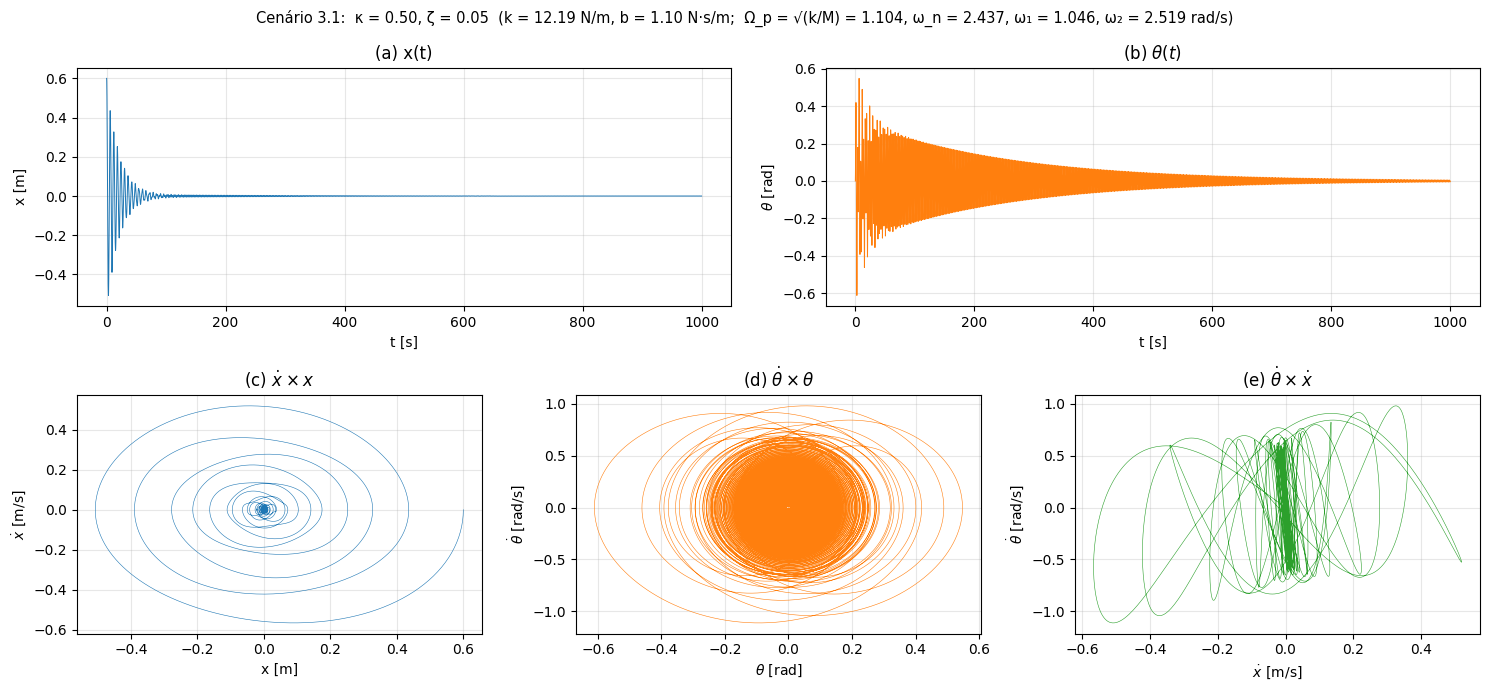

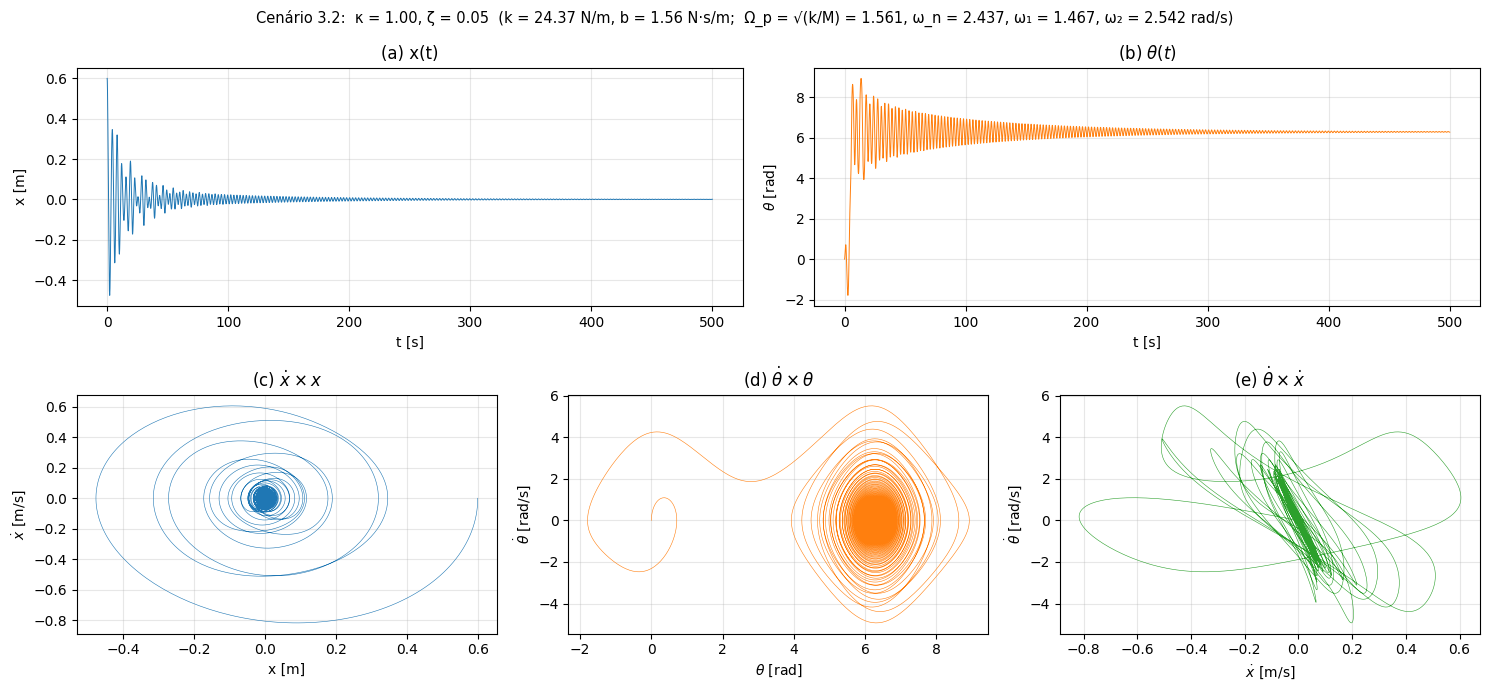

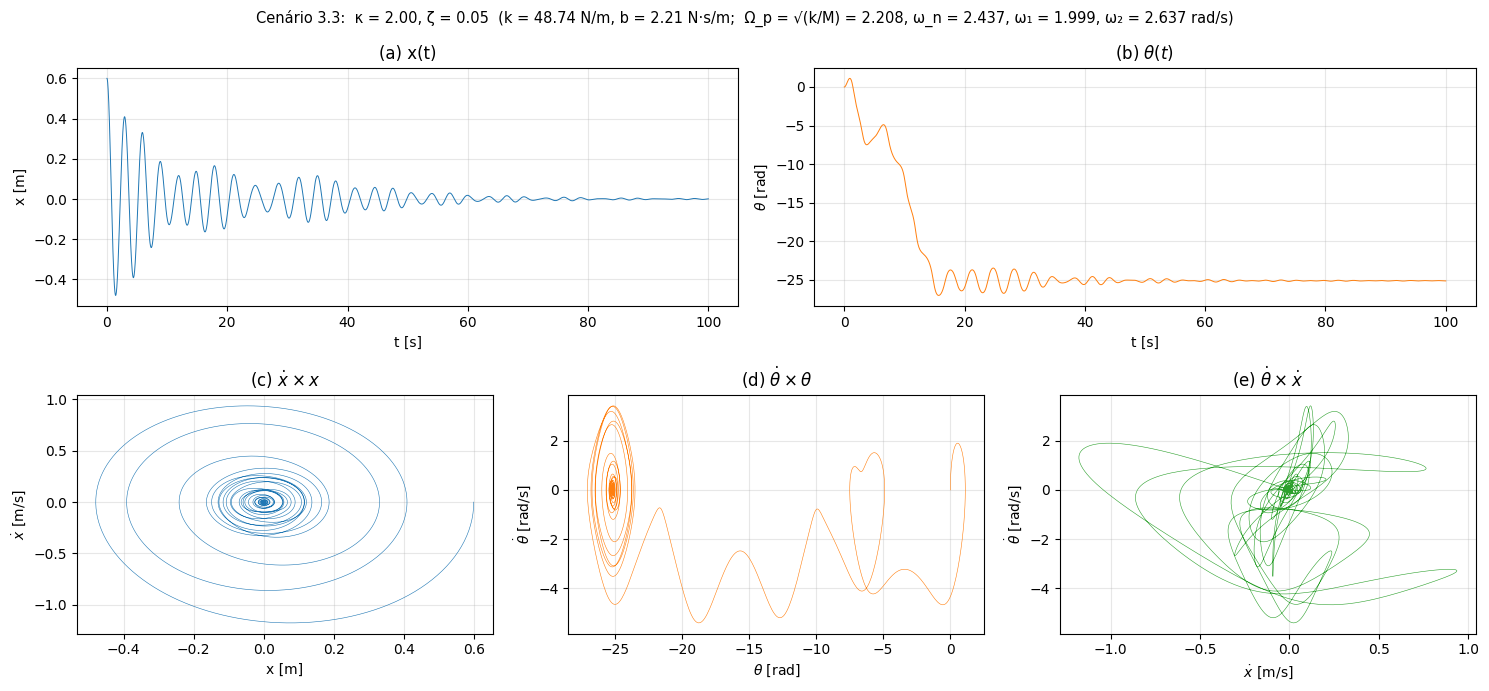

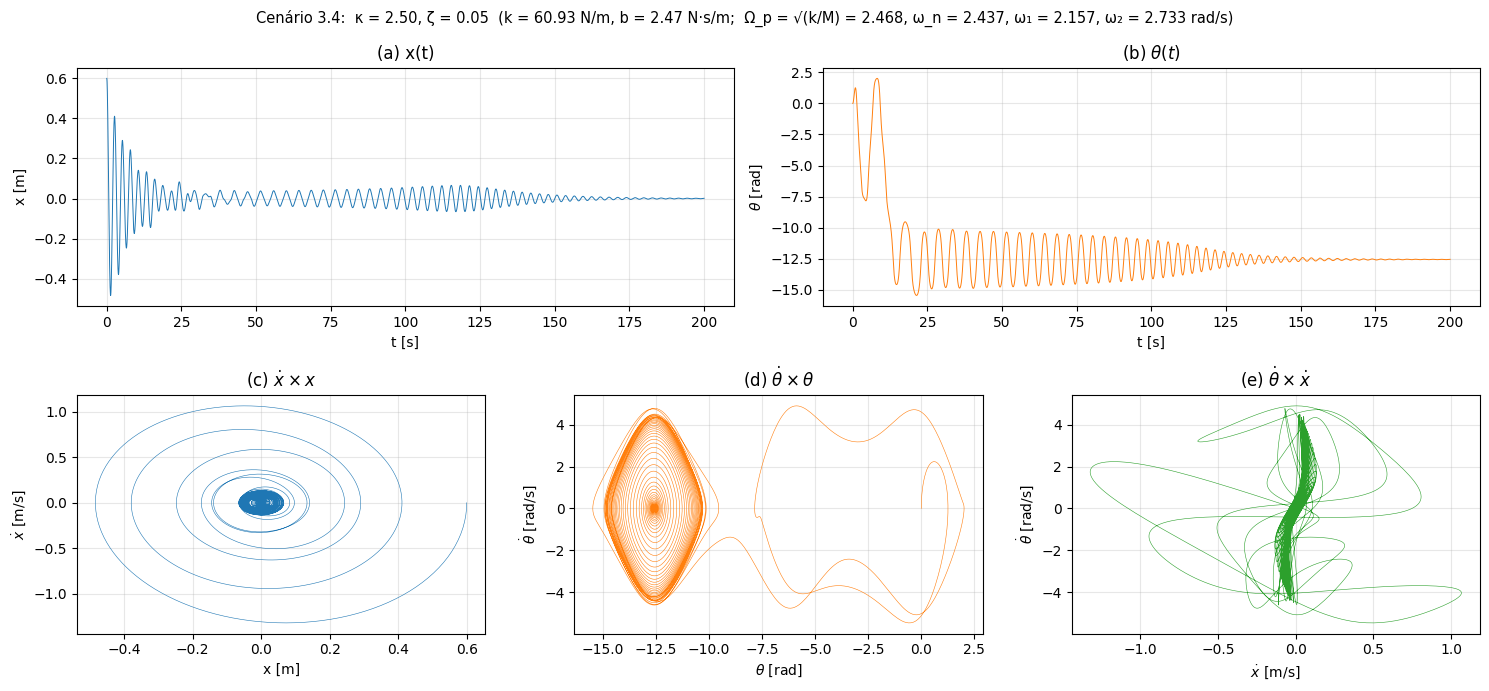

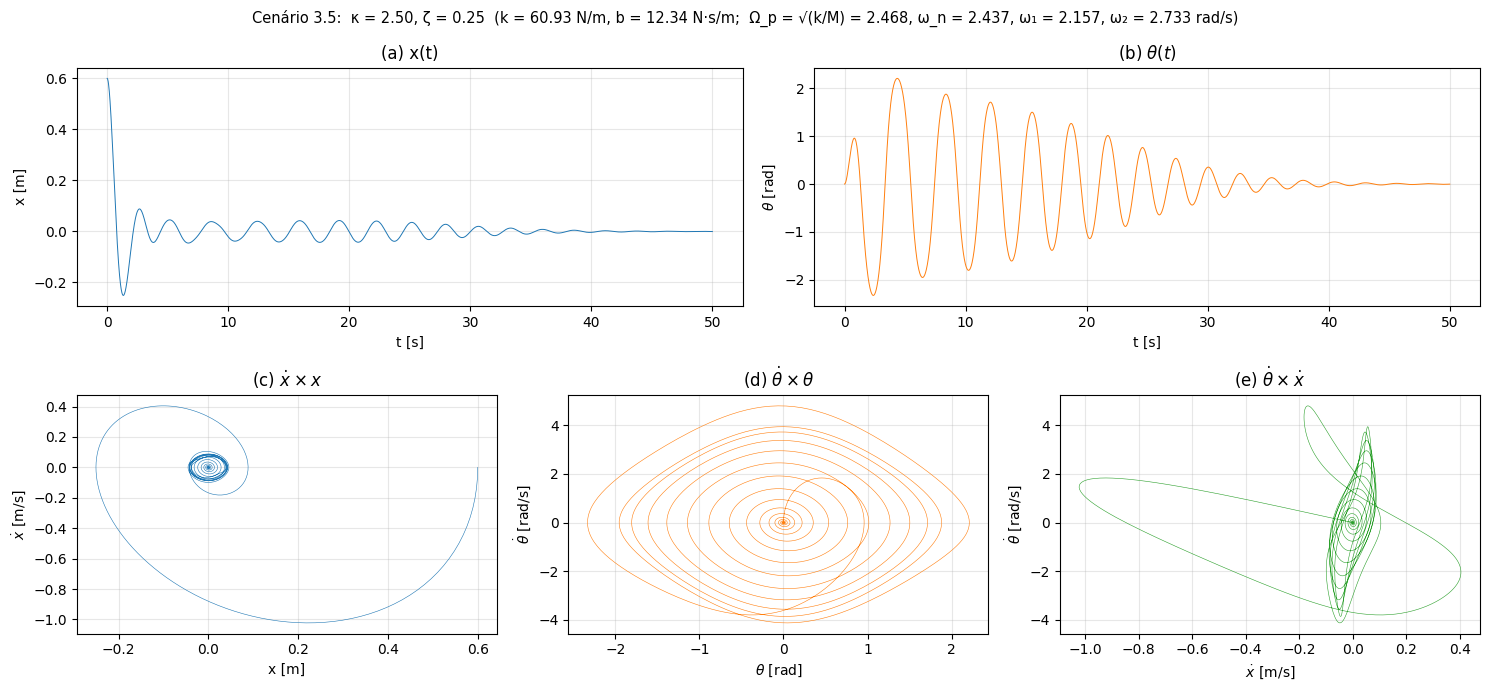

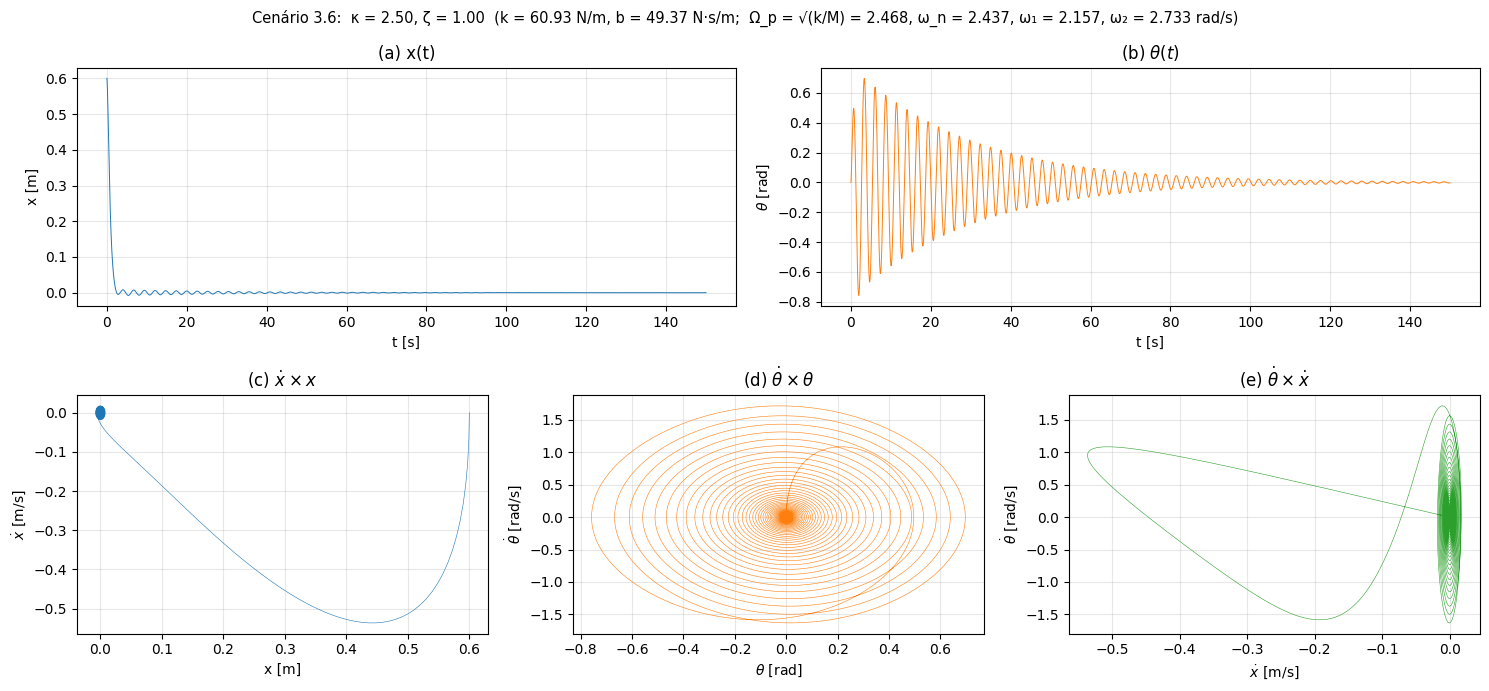

In [9]:
cenarios = {
    "3.1": dict(kappa=0.50, zeta=0.05, tf=1000.0),
    "3.2": dict(kappa=1.00, zeta=0.05, tf=500.0),
    "3.3": dict(kappa=2.00, zeta=0.05, tf=100.0),
    "3.4": dict(kappa=2.50, zeta=0.05, tf=200.0),
    "3.5": dict(kappa=2.50, zeta=0.25, tf=50.0),
    "3.6": dict(kappa=2.50, zeta=1.00, tf=150.0),
}
y0 = [2*0.30, 0.0, 0.0, 0.0]
resultados, params = {}, {}
for nome, c in cenarios.items():
    p = parametros(c["kappa"], c["zeta"]); params[nome] = p
    t_, y_ = simular(p, y0, c["tf"]); resultados[nome] = (t_, y_)
    w1, w2 = frequencias_naturais(p)
    x_, th_, xd_, thd_ = y_

    fig = plt.figure(figsize=(15, 7)); gs = GridSpec(2, 6, figure=fig)
    fig.suptitle(f"Cenário {nome}:  κ = {c['kappa']:.2f}, ζ = {c['zeta']:.2f}  (k = {p['k']:.2f} N/m, b = {p['b']:.2f} N·s/m;  "
                 f"Ω_p = √(k/M) = {np.sqrt(p['k']/p['M']):.3f}, ω_n = {p['wn']:.3f}, ω₁ = {w1:.3f}, ω₂ = {w2:.3f} rad/s)", fontsize=10.5)
    ax = fig.add_subplot(gs[0, :3]); ax.plot(t_, x_, lw=0.7); ax.set_xlabel("t [s]"); ax.set_ylabel("x [m]"); ax.set_title("(a) x(t)")
    ax = fig.add_subplot(gs[0, 3:]); ax.plot(t_, th_, lw=0.7, color="C1"); ax.set_xlabel("t [s]"); ax.set_ylabel(r"$\theta$ [rad]"); ax.set_title(r"(b) $\theta(t)$")
    ax = fig.add_subplot(gs[1, 0:2]); ax.plot(x_, xd_, lw=0.4); ax.set_xlabel("x [m]"); ax.set_ylabel(r"$\dot x$ [m/s]"); ax.set_title(r"(c) $\dot x \times x$")
    ax = fig.add_subplot(gs[1, 2:4]); ax.plot(th_, thd_, lw=0.4, color="C1"); ax.set_xlabel(r"$\theta$ [rad]"); ax.set_ylabel(r"$\dot\theta$ [rad/s]"); ax.set_title(r"(d) $\dot\theta \times \theta$")
    ax = fig.add_subplot(gs[1, 4:6]); ax.plot(xd_, thd_, lw=0.4, color="C2"); ax.set_xlabel(r"$\dot x$ [m/s]"); ax.set_ylabel(r"$\dot\theta$ [rad/s]"); ax.set_title(r"(e) $\dot\theta \times \dot x$")
    plt.tight_layout(); plt.show()

## 3.8 Interpretação física

Para cada cenário comparam-se as frequências naturais não-amortecidas $\omega_1,\omega_2$ (item 3.4) com as frequências desacopladas $\Omega_p=\sqrt{k/M}$ e $\omega_n$,
com os picos do espectro (FFT) das séries simuladas de $x$ e $\theta$, e com os **autovalores do sistema linearizado amortecido**
$\lambda=-\zeta_i\omega_i\pm i\,\omega_i\sqrt{1-\zeta_i^2}$ (modos amortecidos), obtidos de $\mathbf A=\begin{bmatrix}\mathbf 0&\mathbf I\\-\mathbf M^{-1}\mathbf K&-\mathbf M^{-1}\mathbf B\end{bmatrix}$.
Como o amortecimento atua **apenas sobre a placa**, a taxa de decaimento de cada modo depende de quanto a placa participa desse modo — o que explica
as grandes diferenças nos tempos de simulação pedidos.

In [10]:
def modos_amortecidos(p):
    Mm, Bm, Km = matrizes(p)
    A = np.block([[np.zeros((2, 2)), np.eye(2)], [-np.linalg.solve(Mm, Km), -np.linalg.solve(Mm, Bm)]])
    lam_ = np.linalg.eigvals(A)
    lam_ = lam_[np.imag(lam_) >= 0]                        # um de cada par conjugado (ou reais)
    lam_ = lam_[np.argsort(np.abs(lam_))]
    return lam_

def picos_fft(t, s, n_picos=2):
    s = s - np.mean(s); dt = t[1] - t[0]
    S = np.abs(np.fft.rfft(s*np.hanning(len(s)))); f = np.fft.rfftfreq(len(s), dt)
    idx, _ = find_peaks(S, height=0.05*np.max(S))
    idx = idx[np.argsort(S[idx])[::-1]][:n_picos]
    return np.sort(2*np.pi*f[idx])

def inicio_regime_linear(t, th, tol=0.5):
    # primeiro instante a partir do qual |theta - theta_final| < tol para sempre (fim do transitório de grande amplitude)
    th_f = np.mean(th[-len(th)//20:])
    fora = np.where(np.abs(th - th_f) >= tol)[0]
    return (fora[-1] + 1) if len(fora) else 0, th_f

print(" Cen.   κ     ζ    Ω_p     ω_n     ω1      ω2    | modos amortecidos: ω_d1 (ζ1)   ω_d2 (ζ2)   | max|θ|  voltas  t_lin [s] | picos FFT (trecho final) x [rad/s]   θ [rad/s]")
janelas = {}
for nome, c in cenarios.items():
    p = params[nome]; t_, y_ = resultados[nome]
    w1, w2 = frequencias_naturais(p); lam_ = modos_amortecidos(p)
    txt_modos = "   ".join(f"{abs(l.imag):.3f} ({-l.real/abs(l):.3f})" if l.imag > 1e-9 else f"real {l.real:+.3f}" for l in lam_)
    i0, th_f = inicio_regime_linear(t_, y_[1]); janelas[nome] = i0
    voltas = int(np.round(th_f/(2*np.pi)))
    px = picos_fft(t_[i0:], y_[0][i0:]); pth = picos_fft(t_[i0:], y_[1][i0:])
    print(f"  {nome}  {c['kappa']:.2f}  {c['zeta']:.2f}  {np.sqrt(p['k']/p['M']):.3f}  {p['wn']:.3f}  {w1:.3f}  {w2:.3f}  | {txt_modos:34s} | "
          f"{np.max(np.abs(y_[1])):6.2f}   {voltas:+3d}    {t_[i0]:7.1f}  | {np.array2string(px, precision=3):22s} {np.array2string(pth, precision=3):20s}")

 Cen.   κ     ζ    Ω_p     ω_n     ω1      ω2    | modos amortecidos: ω_d1 (ζ1)   ω_d2 (ζ2)   | max|θ|  voltas  t_lin [s] | picos FFT (trecho final) x [rad/s]   θ [rad/s]
  3.1  0.50  0.05  1.104  2.437  1.046  2.519  | 1.045 (0.047)   2.519 (0.002)      |   0.61    +0        6.6  | [1.044 2.517]          [2.517]             
  3.2  1.00  0.05  1.561  2.437  1.467  2.542  | 1.466 (0.045)   2.541 (0.004)      |   8.92    +1      123.9  | [2.539]                [2.539]             
  3.3  2.00  0.05  2.208  2.437  1.999  2.637  | 2.001 (0.035)   2.632 (0.014)      |  27.04    -4       42.8  | [1.976 2.634]          [1.976 2.634]       
  3.4  2.50  0.05  2.468  2.437  2.157  2.733  | 2.161 (0.025)   2.725 (0.024)      |  15.46    -2      128.8  | [2.118]                [2.118]             
  3.5  2.50  0.25  2.468  2.437  2.157  2.733  | 2.364 (0.156)   2.453 (0.089)      |   2.33    +0       27.5  | [2.516]                [2.516]             
  3.6  2.50  1.00  2.468  2.437  2.157  2.73

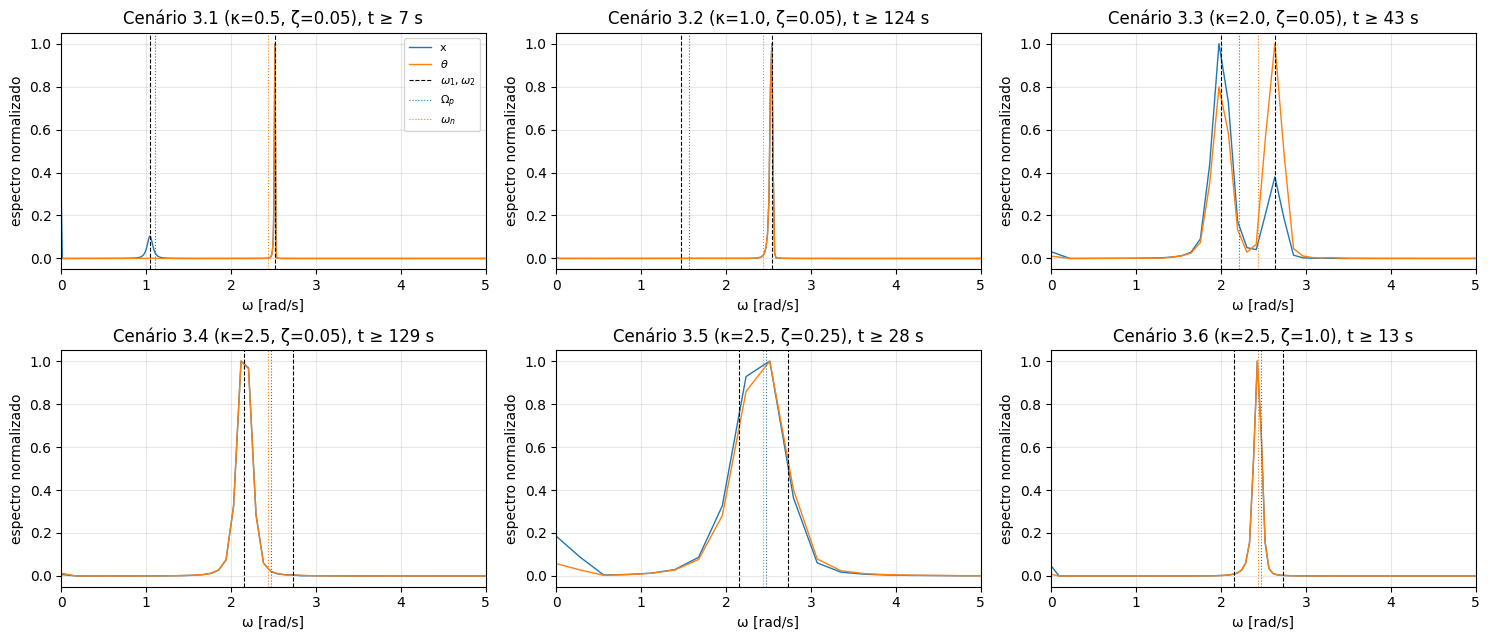

Cenário 3.4, trecho 25 s < t < 110 s (libração de grande amplitude): pico do espectro de θ em ω ≈ 1.553 rad/s (ω1 = 2.157 rad/s); amplitude de θ nesse trecho ≈ 2.40 rad


In [11]:
# espectros de x e theta (normalizados) no trecho final de pequenas oscilações, com as frequências naturais marcadas
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, (nome, c) in zip(axs.ravel(), cenarios.items()):
    p = params[nome]; t_, y_ = resultados[nome]; dt = t_[1] - t_[0]; i0 = janelas[nome]
    for s, rot, cor in [(y_[0][i0:], "x", "C0"), (y_[1][i0:], r"$\theta$", "C1")]:
        S = np.abs(np.fft.rfft((s - s.mean())*np.hanning(len(s)))); f = 2*np.pi*np.fft.rfftfreq(len(s), dt)
        ax.plot(f, S/S.max(), lw=1, color=cor, label=rot)
    w1, w2 = frequencias_naturais(p)
    ax.axvline(w1, color="k", ls="--", lw=0.8, label=r"$\omega_1,\omega_2$"); ax.axvline(w2, color="k", ls="--", lw=0.8)
    ax.axvline(np.sqrt(p["k"]/p["M"]), color="C0", ls=":", lw=0.8, label=r"$\Omega_p$"); ax.axvline(p["wn"], color="C1", ls=":", lw=0.8, label=r"$\omega_n$")
    ax.set_xlim(0, 5); ax.set_title(f"Cenário {nome} (κ={c['kappa']}, ζ={c['zeta']}), t ≥ {t_[i0]:.0f} s"); ax.set_xlabel("ω [rad/s]"); ax.set_ylabel("espectro normalizado")
    if nome == "3.1": ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# espectro de theta no trecho de GRANDE amplitude do cenário 3.4 (após as voltas, antes do regime linear)
t_, y_ = resultados["3.4"]; msk = (t_ > 25) & (t_ < 110)
s = y_[1][msk] - y_[1][msk].mean(); S = np.abs(np.fft.rfft(s*np.hanning(len(s)))); f = 2*np.pi*np.fft.rfftfreq(len(s), t_[1]-t_[0])
print(f"Cenário 3.4, trecho 25 s < t < 110 s (libração de grande amplitude): pico do espectro de θ em ω ≈ {f[np.argmax(S)]:.3f} rad/s "
      f"(ω1 = {frequencias_naturais(params['3.4'])[0]:.3f} rad/s); amplitude de θ nesse trecho ≈ {0.5*(y_[1][msk].max()-y_[1][msk].min()):.2f} rad")

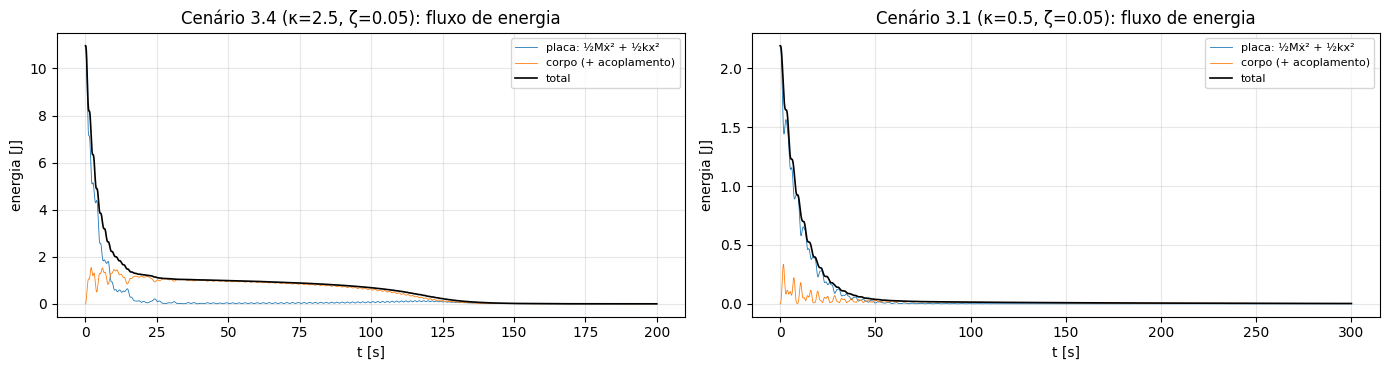

In [12]:
# troca de energia entre placa e corpo no caso sintonizado (3.4) e no desintonizado (3.1)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, nome, tmax in zip(axs, ["3.4", "3.1"], [200, 300]):
    p = params[nome]; t_, y_ = resultados[nome]; x_, th_, xd_, thd_ = y_
    E_placa = 0.5*p["M"]*xd_**2 + 0.5*p["k"]*x_**2
    E_tot = energia(p, y_) - p["m"]*p["g"]*(p["R"] - p["e"])
    msk = t_ <= tmax
    ax.plot(t_[msk], E_placa[msk], lw=0.6, label="placa: ½Mẋ² + ½kx²")
    ax.plot(t_[msk], (E_tot - E_placa)[msk], lw=0.6, label="corpo (+ acoplamento)")
    ax.plot(t_[msk], E_tot[msk], "k", lw=1.2, label="total")
    ax.set_xlabel("t [s]"); ax.set_ylabel("energia [J]"); ax.set_title(f"Cenário {nome} (κ={p['kappa']}, ζ={p['zeta']}): fluxo de energia"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Discussão (ver tabela, espectros e balanço de energia acima).**

* **Transitório não-linear inicial.** A condição inicial $x(0)=2R=0{,}6$ m não é "pequena": a placa parte com aceleração $\ddot x(0)=kx_0/(M+m)$, que atua sobre
  o corpo como o forçamento inercial da Parte 2. O parâmetro equivalente $\epsilon_x=(R/e-1)\,kx_0/[(M+m)g]$ vale $0{,}27$, $0{,}54$, $1{,}09$ e $1{,}36$ para
  κ = 0,5, 1, 2 e 2,5. Para κ ≥ 1 isso basta para **virar o corpo**: nos cenários 3.2, 3.3 e 3.4 ele dá, respectivamente, 1, 4 e 2 voltas completas nos primeiros
  segundos (coluna "voltas"), e termina librando em torno de $\theta=2\pi n$. Em 3.5 a amplitude chega a 2,3 rad sem virar; em 3.1 e 3.6 o regime é linear desde o início.
  A análise de pequenas oscilações vale, portanto, **após** esse transitório — os espectros foram calculados no trecho final ($t\ge t_{lin}$), onde os picos
  coincidem com $\omega_1$ e $\omega_2$.

* **Estrutura dos modos.** Em todos os cenários $\omega_1<\min(\Omega_p,\omega_n)$ e $\omega_2>\max(\Omega_p,\omega_n)$ (entrelaçamento). Quando $\Omega_p$ e $\omega_n$
  estão afastados, cada modo é "quase desacoplado": um é essencialmente a placa oscilando na mola (com o corpo arrastado) e o outro é o corpo oscilando sobre a placa
  quase parada. Quando $\Omega_p\approx\omega_n$ (κ = 2,5) os dois modos são **misturas fortes** de $x$ e $\theta$ e suas frequências se afastam uma da outra
  (*veering*). Como o amortecimento atua só na placa, o $\zeta_i$ de cada modo é proporcional à participação da placa nele.

* **Cenário 3.1** (κ = 0,5: $\Omega_p=1{,}10\ll\omega_n=2{,}44$ rad/s). A placa oscila lentamente ($\omega_1\approx\Omega_p$) e decai com $\zeta_1\approx\zeta$ em ~100 s;
  o corpo, excitado abaixo de sua ressonância (como no cenário 2.1), responde nas **duas frequências**: a da placa (forçada) e a sua própria, $\omega_2\approx\omega_n$.
  Como a placa quase não participa do segundo modo, ele é **quase não amortecido** ($\zeta_2=0{,}002$): a oscilação de $\theta$ em $\omega_2$ persiste por ~800 s —
  daí os 1000 s de simulação. Em $\dot\theta\times\theta$ a espiral converge lentamente; em $\dot x\times x$, rapidamente.

* **Cenário 3.2** (κ = 1: $\Omega_p=1{,}56$ rad/s). O corpo é virado uma vez pelo impulso inicial e passa a oscilar em torno de $2\pi$. Depois disso a estrutura é a de 3.1,
  com acoplamento um pouco maior: o modo do corpo ($\omega_2\approx\omega_n$) tem $\zeta_2=0{,}004$, o dobro de 3.1, e o tempo de decaimento cai para ~400 s.

* **Cenário 3.3** (κ = 2: $\Omega_p=2{,}21$ rad/s, próximo de $\omega_n$). A placa, quase sintonizada, bombeia energia eficientemente para o corpo, que dá quatro voltas
  nos primeiros 15 s enquanto a mola é descarregada. No regime linear subsequente os modos já são bem misturados ($\zeta_1=0{,}035$, $\zeta_2=0{,}014$), o espectro de $x$
  mostra os dois picos e o sistema se acalma em ~80 s, com **batimentos** em $x$ na frequência $\omega_2-\omega_1$.

* **Cenário 3.4** (κ = 2,5, sintonizado, ζ = 0,05). Após duas voltas, o corpo fica em **libração de grande amplitude** (±2,5 rad em torno de $-4\pi$) cuja frequência
  não-linear ($\approx1{,}6$ rad/s, bem abaixo de $\omega_1=2{,}16$, ver célula acima) o **dessintoniza** da placa: o balanço de energia mostra um patamar de ~1 J entre
  25 e 110 s, em que o amortecedor (que só age na placa) quase não extrai energia do corpo. À medida que a amplitude diminui a frequência sobe de volta ao intervalo linear,
  o acoplamento torna-se efetivo (batimentos crescentes em $x$ entre 100 e 130 s) e a energia é então dissipada rapidamente. No regime linear os dois modos repartem o
  amortecimento ($\zeta_1\approx\zeta_2\approx0{,}025$), o que é a situação de decaimento mais eficiente para ζ = 0,05 — mas a não-linearidade adia esse regime.
  O gráfico $\dot\theta\times\dot x$ mostra a figura de Lissajous dos dois modos no trecho final.

* **Cenário 3.5** (κ = 2,5, ζ = 0,25). Amortecimento forte: a placa perde quase toda a sua energia em um ciclo, o corpo atinge 2,3 rad sem virar e a resposta decai em
  ~40 s. Os modos amortecidos têm $\zeta_1=0{,}16$ e $\zeta_2=0{,}09$ e frequências tão próximas (2,36 e 2,45 rad/s) que o espectro apresenta um único pico largo;
  o movimento de $x$ passa a ser essencialmente a resposta da placa ao corpo (pequenas oscilações forçadas em $\omega\approx\omega_n$).

* **Cenário 3.6** (κ = 2,5, ζ = 1). Amortecimento **excessivo**: o amortecedor "trava" a placa, que retorna a $x\approx0$ sem oscilar (modo 1 quase crítico, $\zeta_1=0{,}97$).
  Mas então o corpo volta a ser um oscilador sobre base quase fixa, com $\omega_2=\omega_n$ e **pouquíssimo amortecimento** ($\zeta_2=0{,}015$): embora a amplitude seja
  pequena (0,76 rad), o modo do corpo persiste por ~150 s — mais do que em 3.5. É o mesmo fenômeno dos absorvedores dinâmicos sintonizados (TMD): existe um amortecimento
  **ótimo** da massa secundária e, acima dele, o acoplamento dissipativo se perde (ver item 3.9b).

Em síntese, os valores de $\omega_1,\omega_2$ e, principalmente, a participação da placa em cada modo (que determina os $\zeta_i$) explicam o conteúdo em frequência
das séries no regime de pequenas oscilações e o tempo de decaimento em cada cenário; a amplitude da condição inicial, por sua vez, decide se a análise linear
se aplica desde o início (3.1, 3.6) ou só depois de um transitório com voltas completas (3.2–3.4).

## 3.9 Exploração do modelo

### (a) Frequências naturais e formas modais em função de $\kappa$ (*veering*)

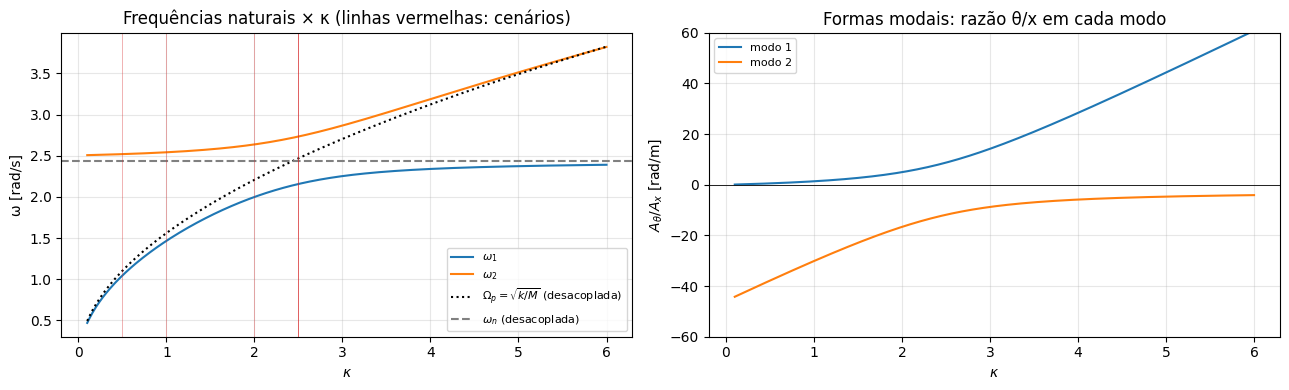

In [13]:
kappas = np.linspace(0.1, 6.0, 300)
W = np.array([frequencias_naturais(parametros(kp, 0.0)) for kp in kappas])
Op = np.array([np.sqrt(parametros(kp, 0.0)["k"]/parametros(kp, 0.0)["M"]) for kp in kappas])
wn0 = parametros(1.0, 0.0)["wn"]

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(kappas, W[:, 0], label=r"$\omega_1$"); axs[0].plot(kappas, W[:, 1], label=r"$\omega_2$")
axs[0].plot(kappas, Op, "k:", label=r"$\Omega_p=\sqrt{k/M}$ (desacoplada)"); axs[0].axhline(wn0, color="gray", ls="--", label=r"$\omega_n$ (desacoplada)")
for c in cenarios.values(): axs[0].axvline(c["kappa"], color="C3", lw=0.5, alpha=0.5)
axs[0].set_xlabel(r"$\kappa$"); axs[0].set_ylabel("ω [rad/s]"); axs[0].set_title("Frequências naturais × κ (linhas vermelhas: cenários)"); axs[0].legend(fontsize=8)

# formas modais: razão A_theta/A_x (rad/m) em cada modo
razoes = []
for kp in kappas:
    p = parametros(kp, 0.0); Mm, _, Km = matrizes(p)
    w2, V = np.linalg.eig(np.linalg.solve(Mm, Km)); order = np.argsort(w2.real); V = V[:, order]
    razoes.append([V[1, 0]/V[0, 0], V[1, 1]/V[0, 1]])
razoes = np.array(razoes)
axs[1].plot(kappas, razoes[:, 0], label="modo 1"); axs[1].plot(kappas, razoes[:, 1], label="modo 2")
axs[1].axhline(0, color="k", lw=0.6); axs[1].set_ylim(-60, 60)
axs[1].set_xlabel(r"$\kappa$"); axs[1].set_ylabel(r"$A_\theta/A_x$ [rad/m]"); axs[1].set_title("Formas modais: razão θ/x em cada modo"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### (b) Amortecimento modal em função de $\zeta$ no caso sintonizado: existe um ζ ótimo

Varia-se $\zeta$ (com κ = 2,5) e calculam-se os fatores de amortecimento dos dois modos a partir dos autovalores do sistema linearizado.
O menor dos dois ($\min\zeta_i$) governa o tempo de extinção da resposta.

ζ ótimo (maximiza o menor amortecimento modal): ζ ≈ 0.230, min ζ_i ≈ 0.101


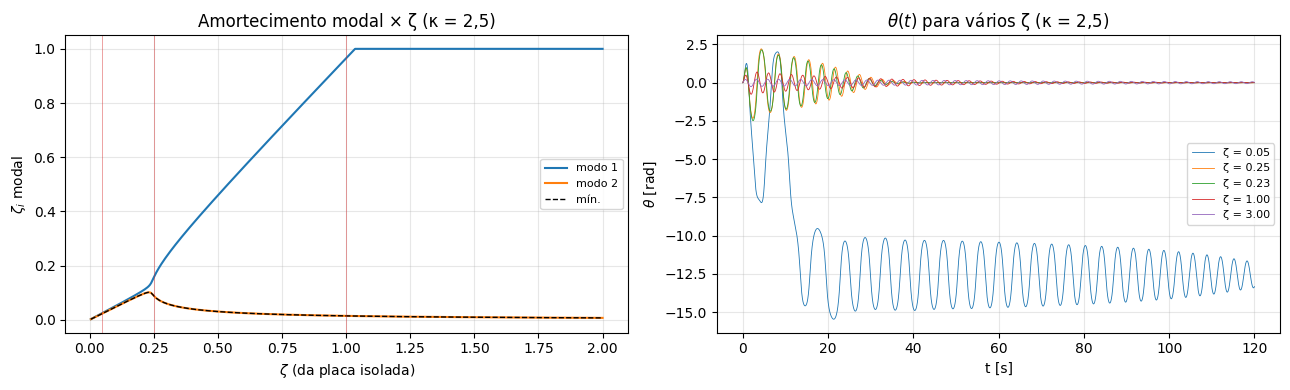

In [14]:
zetas = np.linspace(0.005, 2.0, 400)
zi = []
for z in zetas:
    lam_ = modos_amortecidos(parametros(2.5, z))
    zi.append([-l.real/abs(l) for l in lam_])
zi = np.array([z_ + [np.nan]*(2 - len(z_)) if len(z_) < 2 else z_[:2] for z_ in zi])
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(zetas, zi[:, 0], label="modo 1"); axs[0].plot(zetas, zi[:, 1], label="modo 2"); axs[0].plot(zetas, np.nanmin(zi, axis=1), "k--", lw=1, label="mín.")
axs[0].set_xlabel(r"$\zeta$ (da placa isolada)"); axs[0].set_ylabel(r"$\zeta_i$ modal"); axs[0].set_title("Amortecimento modal × ζ (κ = 2,5)"); axs[0].legend(fontsize=8)
for c in cenarios.values():
    if c["kappa"] == 2.5: axs[0].axvline(c["zeta"], color="C3", lw=0.5, alpha=0.6)
izmax = np.nanargmax(np.nanmin(zi, axis=1)); print(f"ζ ótimo (maximiza o menor amortecimento modal): ζ ≈ {zetas[izmax]:.3f}, min ζ_i ≈ {np.nanmin(zi, axis=1)[izmax]:.3f}")

for z in [0.05, 0.25, zetas[izmax], 1.0, 3.0]:
    t_, y_ = simular(parametros(2.5, z), y0, 120.0)
    axs[1].plot(t_, y_[1], lw=0.6, label=f"ζ = {z:.2f}")
axs[1].set_xlabel("t [s]"); axs[1].set_ylabel(r"$\theta$ [rad]"); axs[1].set_title(r"$\theta(t)$ para vários ζ (κ = 2,5)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### (c) Regime não-linear: grande oscilação inicial do corpo

Partindo de $\theta_0$ grande (corpo quase invertido) com a placa em repouso em $x=0$, compara-se o modelo não-linear com o linearizado
(integrado com as mesmas condições iniciais). A placa, agora, é posta em movimento pelo corpo.

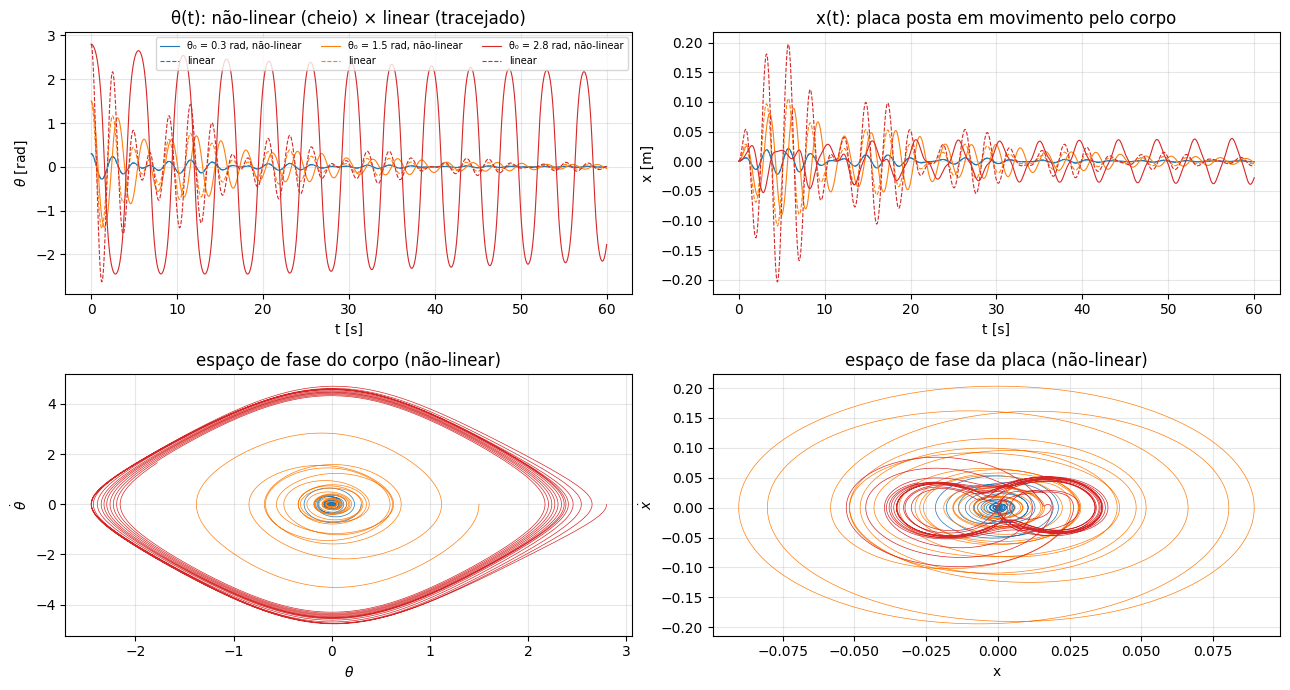

In [15]:
def f_linear(t, y, p):
    Mm, Bm, Km = matrizes(p)
    q = y[:2]; qd = y[2:]
    qdd = np.linalg.solve(Mm, -Bm @ qd - Km @ q)
    return [qd[0], qd[1], qdd[0], qdd[1]]

p = parametros(2.5, 0.05)
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for th0, cor in [(0.3, "C0"), (1.5, "C1"), (2.8, "C3")]:
    y0_ = [0.0, th0, 0.0, 0.0]
    t_, y_ = simular(p, y0_, 60.0)
    sol = solve_ivp(f_linear, (0, 60.0), y0_, t_eval=t_, args=(p,), rtol=1e-9, atol=1e-12)
    axs[0, 0].plot(t_, y_[1], color=cor, lw=0.8, label=f"θ₀ = {th0} rad, não-linear"); axs[0, 0].plot(t_, sol.y[1], color=cor, lw=0.8, ls="--", label="linear")
    axs[0, 1].plot(t_, y_[0], color=cor, lw=0.8); axs[0, 1].plot(t_, sol.y[0], color=cor, lw=0.8, ls="--")
    axs[1, 0].plot(y_[1], y_[3], color=cor, lw=0.5); axs[1, 1].plot(y_[0], y_[2], color=cor, lw=0.5)
axs[0, 0].set_xlabel("t [s]"); axs[0, 0].set_ylabel(r"$\theta$ [rad]"); axs[0, 0].set_title("θ(t): não-linear (cheio) × linear (tracejado)"); axs[0, 0].legend(fontsize=7, ncol=3)
axs[0, 1].set_xlabel("t [s]"); axs[0, 1].set_ylabel("x [m]"); axs[0, 1].set_title("x(t): placa posta em movimento pelo corpo")
axs[1, 0].set_xlabel(r"$\theta$"); axs[1, 0].set_ylabel(r"$\dot\theta$"); axs[1, 0].set_title("espaço de fase do corpo (não-linear)")
axs[1, 1].set_xlabel("x"); axs[1, 1].set_ylabel(r"$\dot x$"); axs[1, 1].set_title("espaço de fase da placa (não-linear)")
plt.tight_layout(); plt.show()

**Observações da exploração.**

* As curvas $\omega_{1,2}(\kappa)$ nunca se cruzam: ao passar pela sintonia ($\kappa\approx2{,}4$) elas se **repelem** (*veering*) e as formas modais trocam de caráter —
  o modo 1 deixa de ser "placa" para ser "corpo" e vice-versa; na sintonia ambos os modos têm participação comparável de $x$ e $\theta$, com sinais opostos
  (modo em fase e modo em oposição de fase).
* Há um **$\zeta$ ótimo** ($\approx0{,}23$ para κ = 2,5) para o decaimento global: para ζ pequeno o modo do corpo mal é amortecido; para ζ grande a placa se
  imobiliza e o corpo volta a oscilar livremente sobre base fixa (cenário 3.6). A curva do menor amortecimento modal é a quantidade a maximizar no projeto de um
  absorvedor dinâmico. Note que, com ζ = 0,05, o corpo chega a virar no transitório, enquanto para ζ ≥ 0,23 a placa é freada antes de conseguir virá-lo.
* Para grandes $\theta_0$ o modelo linear erra o período (que cresce com a amplitude, Parte 1) e a amplitude de $x$ induzida; para $\theta_0=2{,}8$ rad o corpo
  quase atinge a posição invertida e a resposta é fortemente não-senoidal, enquanto o modelo linear ainda prevê uma oscilação harmônica amortecida.
  O amortecimento da placa continua extraindo energia do corpo, mas a taxa depende da amplitude (a frequência não-linear do corpo sai da sintonia com a placa).